# WP07 — Veri entegrasyonu, heterojen graf ve karar kapısı

**Öğren → Gerçek tablo → Görsel → Sızıntı denetimi → Doğrulama → Karar.**

WP00–WP06 onaylandı. Bu notebook yeni ham kaynak açmaz; kayıtlı ve hash doğrulamalı küçük QA çıktılarından çalışır. Nihai etiket, eksik modalite stratejisi ve model giriş şeması seçilmez. İnceleme HeteroData nesneleri `training_ready=False` taşır; x/y, split, negatif örnek veya model yoktur.

Kanonik kimlik kaynak ID'dir; node_index ise yalnız yeniden üretilebilir depolama sırasıdır. Source/target kenarın uç tiplerini, target rolü ise DrugBank'ın biyolojik ilişki rolünü anlatır; bu iki “target” anlamı karıştırılmaz.

In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'));sys.path.insert(0,str(ROOT/'.deps/pyg'))
import pandas as pd,numpy as np,matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display
import torch
from torch_geometric.data import HeteroData
QA=ROOT/'reports/qa/WP07';FIG=ROOT/'reports/figures/WP07';FIG.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_rows',150);pd.set_option('display.max_columns',30);pd.set_option('display.max_colwidth',90)
def read(name): return pd.read_csv(QA/name,keep_default_na=False)
summary=json.loads((QA/'integration_summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame([summary]).drop(columns=['role_edges','scenarios']))
drugs=read('drug_nodes.csv');proteins=read('protein_nodes.csv');pt=read('pt_audit_nodes.csv')
display(drugs.head(5));display(proteins.head(5));display(pt.head(5))

,cohort,proteins,external_pt_classes_audit,external_positive_pairs,typed_drug_protein_edges,chemistry_qc_available,molecule_review,protein_available,strict_human_proteins,k12_scope_review_proteins,context_without_features,context_in_review_graphs,prior_files_verified,training_ready,labels_in_encoder,negative_samples,splits_created
0,62,141,1061,6416,476,54,8,60,63,23,80,0,317,False,False,0,False


,drug_id,node_index
0,DB00199,0
1,DB00207,1
2,DB00254,2
3,DB00259,3
4,DB00301,4


,accession,node_index
0,A0A0H2XJ39,0
1,B2ZTR6,1
2,B4YQT9,2
3,C3T8E2,3
4,D6R448,4


,pt_cui,node_index
0,C0000731,0
1,C0000737,1
2,C0000768,2
3,C0000786,3
4,C0000833,4


**Yorum:** 62 ilaç ve 141 protein korunur. 1061 PT CUI, tüm kohortta gözlenmiş kaynak sözlüğüdür; nihai öğrenme sözlüğü değildir. Aynı ana ilacın tuzu bağımsız drug düğümü yapılmadı. Proteinler PPI eşleşmesi yok diye elenmez.

## 1. Heterojen graf ve hedef deposu

Farklı düğüm ve kenar tipleri heterojen grafı oluşturur. İlaç–protein ilişkileri yönlü ve role özgüdür. STRING ilişkileri kaynakta yönsüzdür; PyG iki yönü iki indeks sütunu olarak saklar. SIDER pozitifleri ayrı hedef deposundadır; inceleme grafındaki SE düğümlerine hedef veya ters hedef kenarı bağlanmaz.

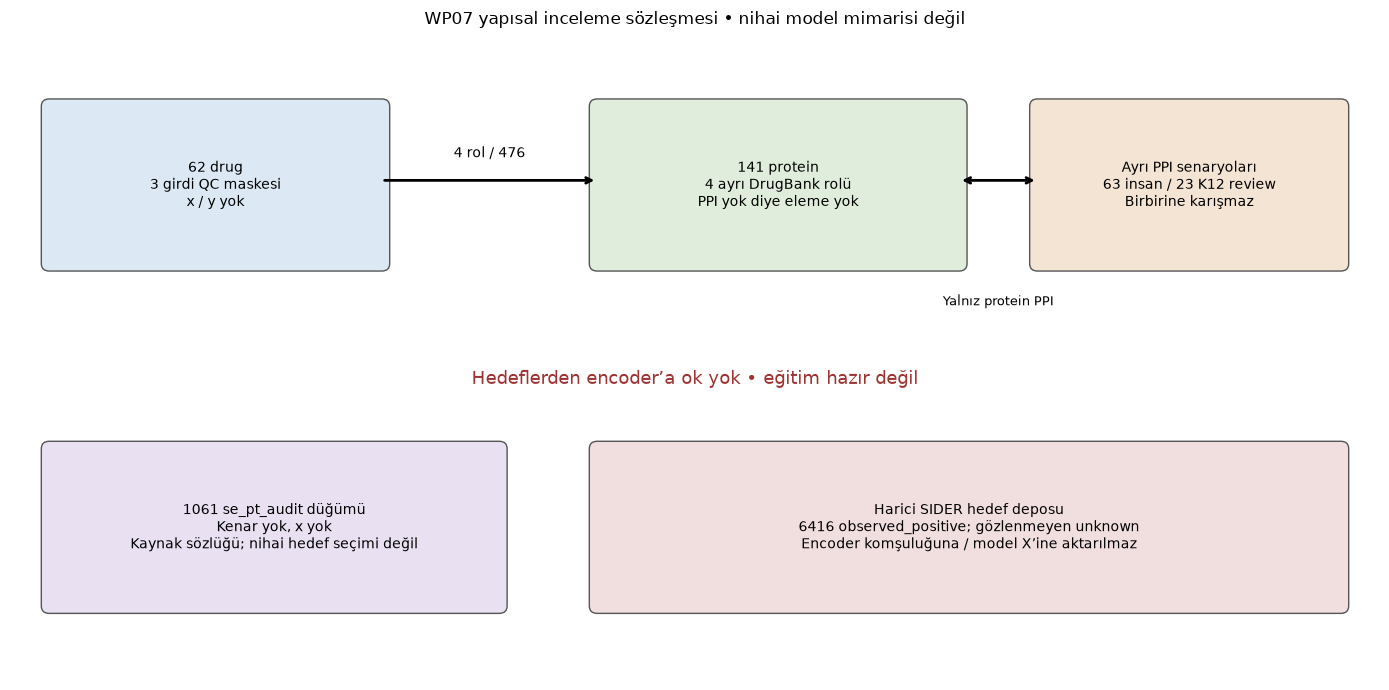

,senaryo,drug,protein,SE_QA,tipli_kenar,training_ready
0,no_ppi,62,141,1061,4,False
1,human_150,62,141,1061,5,False
2,human_400,62,141,1061,5,False
3,human_700,62,141,1061,5,False
4,human_900,62,141,1061,5,False
5,k12_review_700,62,141,1061,5,False


HeteroData(
  scenario='human_700',
  training_ready=False,
  purpose='WP07_structure_review_only',
  drug={
    num_nodes=62,
    canonical_ids=[62],
    chemistry_qc_available=[62],
    protein_modality_available=[62],
    molecule_review=[62],
  },
  protein={
    num_nodes=141,
    canonical_ids=[141],
  },
  se_pt_audit={
    num_nodes=1061,
    canonical_ids=[1061],
  },
  (drug, target, protein)={ edge_index=[2, 241] },
  (drug, enzyme, protein)={ edge_index=[2, 78] },
  (drug, transporter, protein)={ edge_index=[2, 135] },
  (drug, carrier, protein)={ edge_index=[2, 22] },
  (protein, ppi_human_review, protein)={ edge_index=[2, 368] }
)

In [2]:
fig,ax=plt.subplots(figsize=(14,7));ax.set(xlim=(0,14),ylim=(0,7));ax.axis('off')
def box(x,y,w,h,text,color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=.08',facecolor=color,edgecolor='#555'))
    ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=10)
box(.4,4.5,3.4,1.7,'62 drug\n3 girdi QC maskesi\nx / y yok','#dce9f4')
box(6,4.5,3.7,1.7,'141 protein\n4 ayrı DrugBank rolü\nPPI yok diye eleme yok','#e0eddc')
box(10.5,4.5,3.1,1.7,'Ayrı PPI senaryoları\n63 insan / 23 K12 review\nBirbirine karışmaz','#f4e4d4')
box(.4,.8,4.6,1.7,'1061 se_pt_audit düğümü\nKenar yok, x yok\nKaynak sözlüğü; nihai hedef seçimi değil','#e9e0f1')
box(6,.8,7.6,1.7,'Harici SIDER hedef deposu\n6416 observed_positive; gözlenmeyen unknown\nEncoder komşuluğuna / model X’ine aktarılmaz','#f1dfdf')
ax.annotate('',xy=(6,5.4),xytext=(3.8,5.4),arrowprops=dict(arrowstyle='->',lw=2));ax.text(4.9,5.65,'4 rol / 476',ha='center')
ax.annotate('',xy=(9.7,5.4),xytext=(10.5,5.4),arrowprops=dict(arrowstyle='<->',lw=2));ax.text(10.1,4.05,'Yalnız protein PPI',ha='center',fontsize=9)
ax.text(7,3.2,'Hedeflerden encoder’a ok yok • eğitim hazır değil',ha='center',fontsize=13,color='#9d3333')
ax.set_title('WP07 yapısal inceleme sözleşmesi • nihai model mimarisi değil');plt.tight_layout();plt.savefig(FIG/'01_review_schema.png',dpi=160);plt.show()
graphs=torch.load(QA/'heterodata_review_scenarios.pt',weights_only=False,map_location='cpu') # yalnız bu projede yeni üretilmiş güvenilir dosya
display(pd.DataFrame([{'senaryo':k,'drug':g['drug'].num_nodes,'protein':g['protein'].num_nodes,'SE_QA':g['se_pt_audit'].num_nodes,'tipli_kenar':len(g.edge_types),'training_ready':g.training_ready} for k,g in graphs.items()]))
display(graphs['human_700'])

**Yorum:** Grafik bir veri sözleşmesi çizimidir; mesaj geçişi uygulanmadı. HeteroData nesnelerinin tümünde aynı 62/141/1061 düğüm paydası bulunur. PyG'nin SE düğümlerinin ilişki kenarı olmadığına dair uyarısı beklenen bilinçli ayrımdır, eksik hedef kenarı ekleme talimatı değildir. PT düğümlerinin sayılması, PT sayısını ilaç özelliği yapmak anlamına gelmez. Dosya yalnız güvenilir yerel üretimden yüklenir; eski `.pt` yüklenmez.

## 2. Eksik modalite ve QC maskeleri

Eksik bir özellik biyolojik sıfır değildir. İnceleme bayrağı da molekülün kesin yanlış olduğu anlamına gelmez. Kimya QC ve protein bulunurluğu kaynak girdisinden gelir; `has_pt` veya kategori yoğunluğu bunları belirlemez.

,drug_id,node_index,name,cid,chemistry_qc_available,molecule_review,protein_modality_available,review_flags,target_protein_count_QA,enzyme_protein_count_QA,transporter_protein_count_QA,carrier_protein_count_QA,human_strict_protein_count_QA,k12_scope_review_protein_count_QA
0,DB00199,0,Erythromycin,12560,True,False,True,,2,3,6,0,11,0
1,DB00207,1,Azithromycin,447043,True,False,True,,1,1,2,0,4,0
2,DB00254,2,Doxycycline,54671203,True,False,True,,0,1,2,1,4,0
3,DB00259,3,Sulfanilamide,5333,True,False,True,,1,0,0,0,0,1
4,DB00301,4,Flucloxacillin,21319,True,False,True,,1,1,1,0,2,0
5,DB00303,5,Ertapenem,150610,True,False,True,,8,1,0,1,2,6
6,DB00319,6,Piperacillin,43672,True,False,True,,4,0,2,0,2,0
7,DB00359,7,Sulfadiazine,5215,True,False,True,,2,3,0,0,3,1
8,DB00415,8,Ampicillin,6249,True,False,True,,7,0,4,1,5,0
9,DB00417,9,Phenoxymethylpenicillin,6869,True,False,True,,4,0,0,0,1,1


,chemistry_qc_available,protein_modality_available,drugs
0,False,False,1
1,False,True,7
2,True,False,1
3,True,True,53


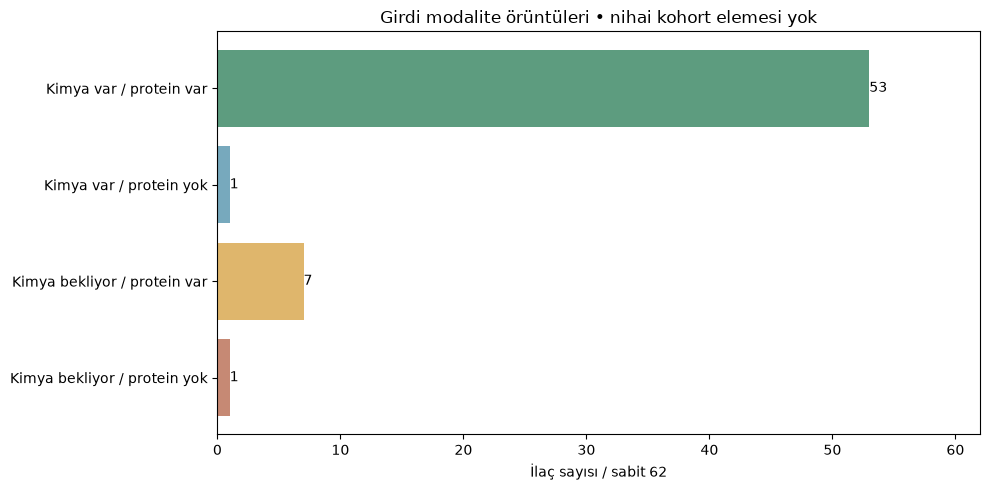

,drug_id,name,molecule_review,review_flags,protein_modality_available
21,DB00578,Carbenicillin,True,unspecified_atom_stereo,True
26,DB00684,Tobramycin,False,,False
31,DB00798,Gentamicin,True,multiple_components|unspecified_atom_stereo,True
37,DB00978,Lomefloxacin,True,unspecified_atom_stereo,True
39,DB01044,Gatifloxacin,True,unspecified_atom_stereo,True
45,DB01150,Cefprozil,True,unspecified_double_bond_stereo,True
46,DB01155,Gemifloxacin,True,unspecified_atom_stereo,True
47,DB01165,Ofloxacin,True,unspecified_atom_stereo,True
61,DB06799,Methenamine,True,unspecified_atom_stereo,False


In [3]:
m=read('drug_modality_QA.csv');patterns=read('modality_patterns.csv')
display(m);display(patterns)
fig,ax=plt.subplots(figsize=(10,5));names=['Kimya '+('var' if r.chemistry_qc_available else 'bekliyor')+' / protein '+('var' if r.protein_modality_available else 'yok') for r in patterns.itertuples()]
bars=ax.barh(names,patterns.drugs,color=['#c68974','#dfb66c','#77a9bd','#5d9c7f'][:len(patterns)])
ax.bar_label(bars);ax.set(xlabel='İlaç sayısı / sabit 62',title='Girdi modalite örüntüleri • nihai kohort elemesi yok');ax.set_xlim(0,62);plt.tight_layout();plt.savefig(FIG/'02_modality_patterns.png',dpi=160);plt.show()
display(m[m.molecule_review | ~m.protein_modality_available][['drug_id','name','molecule_review','review_flags','protein_modality_available']])

**Yorum:** WP04'ün sekiz inceleme bayrağı korunur. Tobramycin ve Methenamine eksik protein modalitesiyle kalır; Methenamine aynı zamanda moleküler incelemededir. Complete-case yalnız bir duyarlılık seçeneğidir; ana kohortu otomatik daraltmak değildir. Maskeli ayrı dallar, train-only imputasyon ve complete-case kıyası karar dosyasında karşılaştırılır.

## 3. Biyolojik roller ayrı kenar tipleridir

,kenar,ilac,protein
role,,,
target,241,55,89
enzyme,78,38,30
transporter,135,43,28
carrier,22,19,4


,drug_id,accession,role,sequence_available,evidence_ids
0,DB00254,P02768,carrier,True,DB00254:5
1,DB00303,P02768,carrier,True,DB00303:10
2,DB00415,P02768,carrier,True,DB00415:12
3,DB00438,P02768,carrier,True,DB00438:7
4,DB00485,P02768,carrier,True,DB00485:9
5,DB00512,P02763,carrier,True,DB00512:3
6,DB00512,P02768,carrier,True,DB00512:2
7,DB00512,P19652,carrier,True,DB00512:4
8,DB00512,P70174,carrier,True,DB00512:5
9,DB00537,P02768,carrier,True,DB00537:21


,scenario,source_type,relation,target_type,edge_index_columns
0,no_ppi,drug,target,protein,241
1,no_ppi,drug,enzyme,protein,78
2,no_ppi,drug,transporter,protein,135
3,no_ppi,drug,carrier,protein,22
4,human_150,drug,target,protein,241
5,human_150,drug,enzyme,protein,78
6,human_150,drug,transporter,protein,135
7,human_150,drug,carrier,protein,22
8,human_150,protein,ppi_human_review,protein,2400
9,human_400,drug,target,protein,241


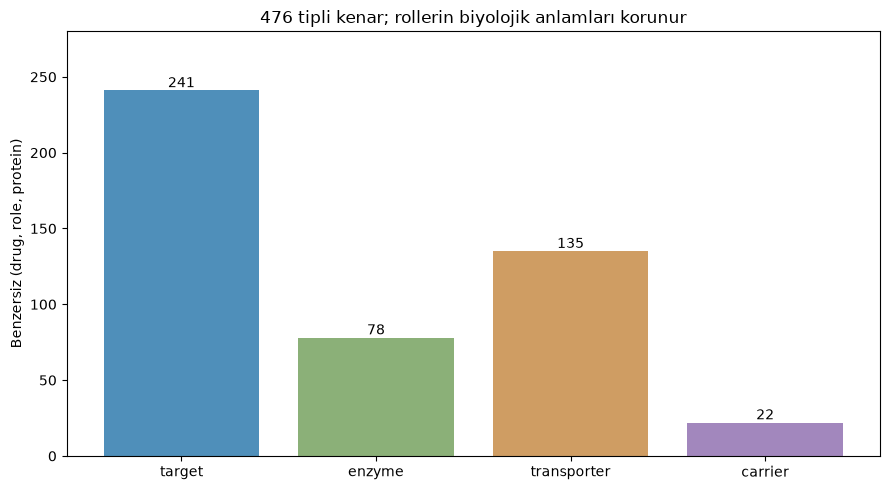

In [4]:
typed=read('typed_drug_protein_edges.csv');roles=typed.groupby('role').agg(kenar=('accession','size'),ilac=('drug_id','nunique'),protein=('accession','nunique')).reindex(['target','enzyme','transporter','carrier'])
display(roles);display(typed.head(12));display(read('edge_counts.csv'))
fig,ax=plt.subplots(figsize=(9,5));bars=ax.bar(roles.index,roles.kenar,color=['#4f8fba','#8bb078','#cf9d63','#a287bd']);ax.bar_label(bars);ax.set(ylabel='Benzersiz (drug, role, protein)',title='476 tipli kenar; rollerin biyolojik anlamları korunur');ax.set_ylim(0,280);plt.tight_layout();plt.savefig(FIG/'03_role_edges.png',dpi=160);plt.show()

**Yorum:** Target bağları tek başına 241; enzyme, transporter ve carrier eklenince 476 tipli kenar var. Aynı ilaç–protein çifti farklı rollerde bulunabilir; rol silinerek tekilleştirmek farklı bir graf üretir. Ters ilişki eklemek sonraki mesaj geçişi tasarımına bağlıdır; burada otomatik ters kenar eklenmez.

## 4. PPI kapsamını ve yönsüz sayımı koruma

,accession
status,
exact_alias_exact_taxon,63
out_of_scope_organism,49
exact_alias_K12_parent_scope_review,23
unmatched_accession_alias,6


,scenario,threshold,unique_undirected_pairs,directed_index_columns,final_choice
0,human_150,150,1200,2400,False
1,human_400,400,583,1166,False
2,human_700,700,184,368,False
3,human_900,900,79,158,False
4,k12_review_700,700,68,136,False


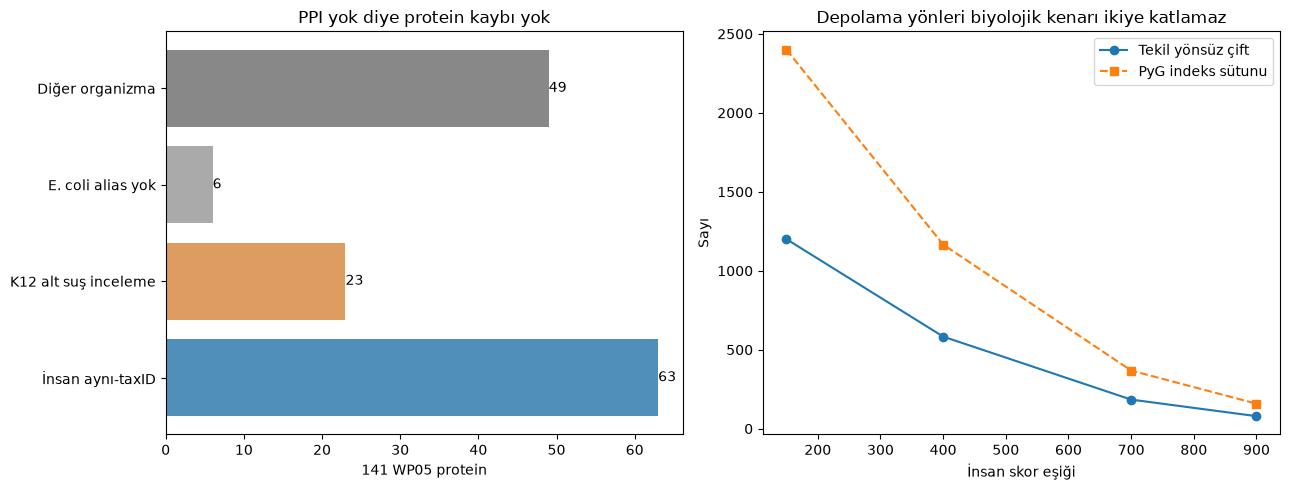

,string_id,network_taxid,protein_name,sequence_feature_available
0,9606.ENSP00000216223,9606,,False
1,9606.ENSP00000216336,9606,,False
2,9606.ENSP00000231449,9606,,False
3,9606.ENSP00000231454,9606,,False
4,9606.ENSP00000233997,9606,,False
5,9606.ENSP00000234347,9606,,False
6,9606.ENSP00000236850,9606,,False
7,9606.ENSP00000242786,9606,,False
8,9606.ENSP00000245907,9606,,False
9,9606.ENSP00000252486,9606,,False


,Özelliksiz context
network_taxid,
9606,40
511145,40


In [5]:
mapping=pd.read_csv(ROOT/'reports/qa/WP06/protein_string_mapping.csv',keep_default_na=False)
scope=mapping.status.value_counts();display(scope.rename('accession').to_frame())
ppi=read('ppi_scenarios.csv');display(ppi)
fig,axs=plt.subplots(1,2,figsize=(13,5))
counts=[63,23,6,49];labs=['İnsan aynı-taxID','K12 alt suş inceleme','E. coli alias yok','Diğer organizma']
bars=axs[0].barh(labs,counts,color=['#4f8fba','#df9c61','#aaa','#888']);axs[0].bar_label(bars);axs[0].set(xlabel='141 WP05 protein',title='PPI yok diye protein kaybı yok')
human=ppi[ppi.scenario.str.startswith('human')];axs[1].plot(human.threshold,human.unique_undirected_pairs,'o-',label='Tekil yönsüz çift');axs[1].plot(human.threshold,human.directed_index_columns,'s--',label='PyG indeks sütunu');axs[1].legend();axs[1].set(xlabel='İnsan skor eşiği',ylabel='Sayı',title='Depolama yönleri biyolojik kenarı ikiye katlamaz')
plt.tight_layout();plt.savefig(FIG/'04_ppi_scope_and_counts.png',dpi=160);plt.show()
context=read('context_inventory_no_features.csv');display(context[['string_id','network_taxid','protein_name','sequence_feature_available']].head(10));display(context.groupby('network_taxid').size().rename('Özelliksiz context').to_frame())

**Yorum:** 63 aynı-taxID insan ile 23 K12/MG1655 inceleme kaydı aynı kesinlikte değildir. K12 700 senaryosu ayrı tutulur. İnsan 700'de 184 kaynak çifti 368 indeks sütunu eder; model PPI kullandı demek değildir. 80 context proteininin amino asit özellikleri yoktur; inceleme grafına alınmadılar ve sıfırla doldurulmadılar. Sıfır+maske, öğrenilen tip tokenı, ayrı topolojik temsil veya context kullanmama seçenekleri biyolojik anlamlarıyla karar dosyasındadır.

## 5. Hedef stratejileri ve unknown semantiği

,strategy,classes,positive_pairs,drugs_with_positive,singleton_classes,classes_under5,unknown_pairs,median_positive_per_drug_QA,min_support,max_support
0,PT_CUI_audit,1061,6416,62,406,710,59366,79.5,1,61
1,historical_30_audit,30,1011,61,0,0,849,16.5,7,61


,drug_id,pt_cui,term,status,source
0,DB00199,C0000737,Abdominal pain,observed_positive,reports/qa/WP03/drug_pt_positives.csv
1,DB00199,C0687713,Gastrointestinal pain,observed_positive,reports/qa/WP03/drug_pt_positives.csv
2,DB00199,C0002792,Anaphylactic shock,observed_positive,reports/qa/WP03/drug_pt_positives.csv
3,DB00199,C0232462,Decreased appetite,observed_positive,reports/qa/WP03/drug_pt_positives.csv
4,DB00199,C0003811,Arrhythmia,observed_positive,reports/qa/WP03/drug_pt_positives.csv
5,DB00199,C0008031,Chest pain,observed_positive,reports/qa/WP03/drug_pt_positives.csv
6,DB00199,C0008149,Chlamydial infection,observed_positive,reports/qa/WP03/drug_pt_positives.csv
7,DB00199,C0009676,Confusional state,observed_positive,reports/qa/WP03/drug_pt_positives.csv


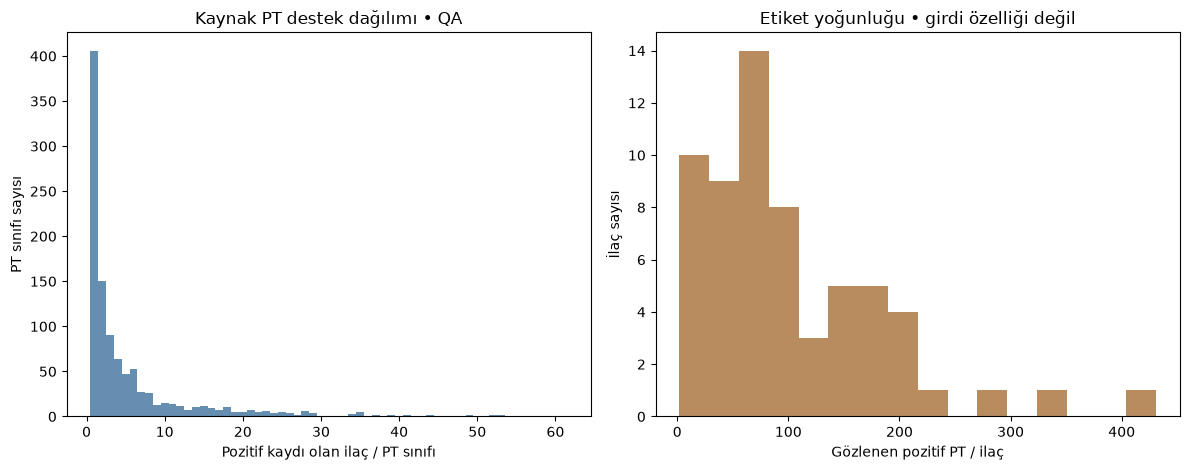

In [6]:
strategies=read('label_strategy_comparison.csv');display(strategies)
labels=read('observed_pt_positives_external.csv');display(labels.head(8))
freq=labels.groupby('pt_cui').drug_id.nunique();perdrug=labels.groupby('drug_id').pt_cui.nunique().reindex(drugs.drug_id,fill_value=0)
fig,axs=plt.subplots(1,2,figsize=(12,4.8));axs[0].hist(freq,bins=np.arange(.5,62.5,1),color='#658eb1');axs[0].set(xlabel='Pozitif kaydı olan ilaç / PT sınıfı',ylabel='PT sınıfı sayısı',title='Kaynak PT destek dağılımı • QA')
axs[1].hist(perdrug,bins=16,color='#b98c60');axs[1].set(xlabel='Gözlenen pozitif PT / ilaç',ylabel='İlaç sayısı',title='Etiket yoğunluğu • girdi özelliği değil');plt.tight_layout();plt.savefig(FIG/'05_label_strategy_QA.png',dpi=160);plt.show()

**Yorum:** 6416 kayıt 1061 PT sınıfında kayıpsız tutulur. 406 singleton ve küçük kohort, sınıf bazında bağımsız değerlendirmeyi sınırlar. Tarihsel 30 projeksiyonunda 61 ilaç/1011 çift vardır; Sulfanilamide'nin kategori pozitifinin olmaması kesin negatif değildir. PT sözlüğünde 59366 gözlenmeyen çift unknown olarak düşünülür; böyle bir yoğun negatif matris üretilmedi. Nihai etiket seti veya destek eşiği seçilmedi.

## 6. Sızıntı sınırı ve inceleme kararları

,field_or_route,risk,WP07_control,verification
0,"PT/CUI, kategori, has_pt, PT sayısı",Hedef/kohort seçilim bilgisi,Encoder grafından ve x şemasından ayrıldı,"Hedef kenarı, global hedef alanı ve x/y enjeksiyon testleri"
1,Raporlama sıklığı / kanıt tekrarı / eski üyelik,Kayıt süreci ve tarihsel seçim izi,QA/provenans sidecar; X allowlist dışında,Fazladan özellik sütunu reddi
2,kalite_skoru / ID sayısal kodu,Keyfi ön ek veya kimlik ezberi,Kimlik yalnız join/index; skor yok,Kimya/protein allowlist ve canonical ID testleri
3,combined_score,Kenar kanıtını protein kalitesi sanma,Yalnız WP06 provenans ve senaryo filtresi; node/edge x yok,Kenar attribute enjeksiyonu reddi
4,Val/test hedefleri ve ters kenarları,Doğrudan komşuluk hedef sızıntısı,İnceleme grafında hiçbir SE ilişki kenarı yok,SE/reverse SE edge reddi; WP08 split sonrası ayrıca test
5,Tüm kohort scaler/özellik/etiket seçimi,Test dağılımı/etiketleriyle seçim,WP07 fit ve split yok; gelecek fit train-only,WP08 spy fit-ID ve label sözlüğü kaynak testleri planlandı
6,Paylaşılan protein/PPI üzerinden test ilaçları,Drug-disjoint sınırının dolaylı ihlali,Tüm-kohort grafı yalnız inceleme nesnesi; eğitim hazır değil,Gelecekte train grafında test ilaç düğümü ve ters ilaç kenarı bulunmamalı
7,QC/input maskesi,Kaynak bulunurluğu biyoloji dışı ayrım yapabilir,Etiketten bağımsız girdi QC; yalnız üç maske tensorü,Maskeli/maskesiz ve kaynak-kapsam duyarlılığı WP08+


,decision_id,topic,option,tradeoff,status
0,D01,Hedef etiket,Tarihsel 30 karşılaştırması,"V6 izlenebilirliği; 61 ilaçta pozitif, semantik bayraklar sürüyor",Nihai hedef olarak onaylanmadı
1,D01,Hedef etiket,Kaynak PT CUI,"62 ilaç, 1061 sınıf; 406 singleton; kavram izi korunur",Kayıpsız denetim sözlüğü; nihai hedef değil
2,D01,Hedef etiket,Semantik incelemeli kategori/PT alt kümesi,Uzman gerekçesi; veriyle seçilecek eşik yalnız train üzerinde,Birleştirme/eleme yapılmadı
3,D02,Eksik ilaç modalitesi,Maskeli ayrı dallar / mevcut modaliteyi kullan,62 ID korunur; boş komşu toplaması biyolojik sıfır sayılmaz,Öneri; encoder/gating kararı bekliyor
4,D02,Eksik ilaç modalitesi,Train-only imputasyon + input maskesi,Kimya için istatistiksel vekil; kimyasal doğrulama değildir,Fit/dolgu yapılmadı; QC bayrağı korunur
5,D02,Eksik ilaç modalitesi,Complete-case duyarlılık analizi,Aynı alt grupta kıyas mümkün; seçilim yanlılığı ve kapsam kaybı,Ana 62 kohortunu daraltma kararı değil
6,D03,80 context proteini,Seed-induced ağ / context kullanma,Özelliği olmayan ek düğüm gerektirmez; bağlam kaybını raporla,İnceleme nesneleri bu seçeneği örnekler; nihai model kararı değil
7,D03,80 context proteini,Öğrenilen tip tokenı + açık maske,Sequence-derived özellik değildir; paylaşılan öğrenilen temsil önyargısı,Gelecekte onay ve ablation gerekir
8,D03,80 context proteini,Topolojiye dayalı ayrı yapısal encoder,Dizi biyokimyası iddiası yok; kapsam/transdüktif yapı etkisi denetlenmeli,Uygulanmadı
9,D03,80 context proteini,Sıfır vektör + maske,Sıfır gerçek AAC/DC veya MW değildir; ölçekleme/degree etkisi ve yapay benzerlik,Varsayılan yapılmadı; maskesiz dolgu kabul edilmez


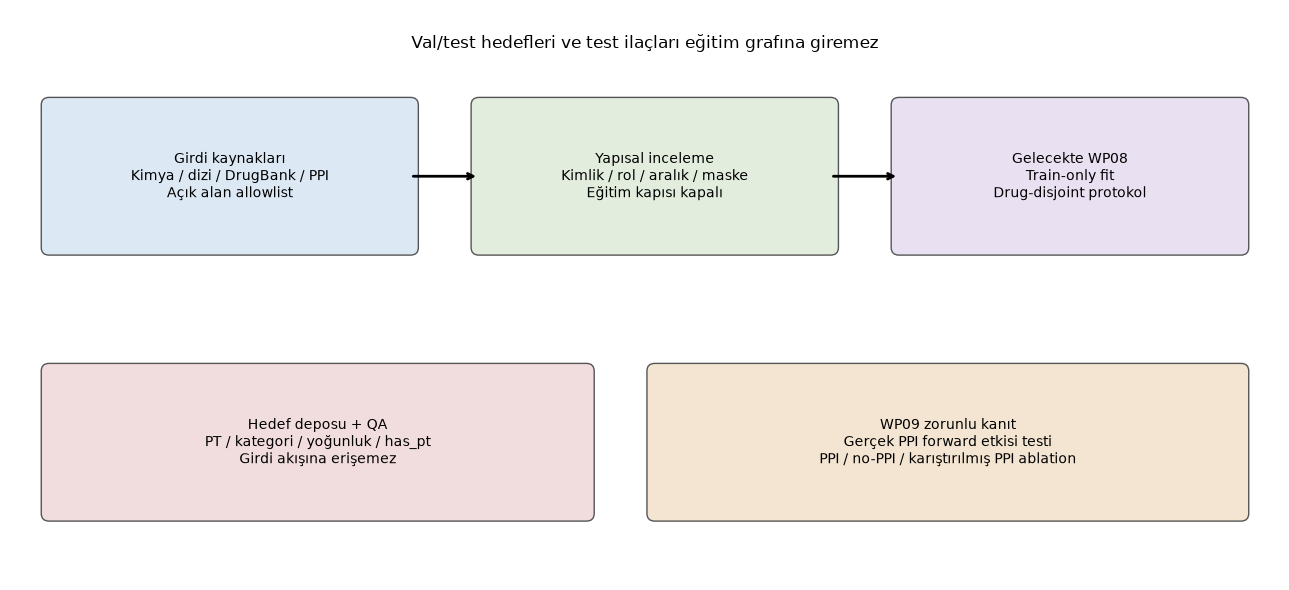

In [7]:
audit=read('leakage_audit.csv');decisions=read('decision_options.csv');display(audit);display(decisions)
fig,ax=plt.subplots(figsize=(13,6));ax.set(xlim=(0,13),ylim=(0,6));ax.axis('off')
box(.4,3.5,3.7,1.5,'Girdi kaynakları\nKimya / dizi / DrugBank / PPI\nAçık alan allowlist','#dce9f4')
box(4.8,3.5,3.6,1.5,'Yapısal inceleme\nKimlik / rol / aralık / maske\nEğitim kapısı kapalı','#e2eddd')
box(9.1,3.5,3.5,1.5,'Gelecekte WP08\nTrain-only fit\nDrug-disjoint protokol','#e9e0f1')
box(.4,.7,5.5,1.5,'Hedef deposu + QA\nPT / kategori / yoğunluk / has_pt\nGirdi akışına erişemez','#f1dddd')
box(6.6,.7,6,1.5,'WP09 zorunlu kanıt\nGerçek PPI forward etkisi testi\nPPI / no-PPI / karıştırılmış PPI ablation','#f3e5d2')
for a,b in [((4.1,4.25),(4.8,4.25)),((8.4,4.25),(9.1,4.25))]:ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='->',lw=2))
ax.text(6.5,5.6,'Val/test hedefleri ve test ilaçları eğitim grafına giremez',ha='center',fontsize=12)
plt.tight_layout();plt.savefig(FIG/'06_leakage_boundary.png',dpi=160);plt.show()

**Yorum:** Bu ayrım gelecekteki eğitim hattını otomatik güvenli yapmaz. İnceleme grafı tüm kohortu içerir; bu yüzden doğrudan train grafı olarak kullanılamaz. WP08'de test ilaç düğümleri ve ileri/ters ilişkileri eğitimden çıkarılmalı, scaler/özellik seçimi yalnız train'de fit edilmeli. Paylaşılan protein/PPI bağlamının sınırı açık protokol kararıdır. PPI encoder ancak forward'da komşuluğu gerçekten kullanınca ve kontrollü ablation ile sınanınca iddia edilebilir.

## 7. Etkileşimli modalite envanteri ve kapanış

In [8]:
import plotly.graph_objects as go
columns=['chemistry_qc_available','protein_modality_available','molecule_review']
z=m[columns].astype(int).to_numpy();hover=np.repeat((m.drug_id+' | '+m.name+' | QC: '+m.review_flags).to_numpy()[:,None],3,axis=1)
fig=go.Figure(go.Heatmap(z=z,x=['Kimya QC var','Protein var','Molekül incelemede'],y=m.drug_id,text=hover,hovertemplate='%{text}<br>%{x}: %{z}<extra></extra>',zmin=0,zmax=1,colorscale=[[0,'#eee'],[1,'#4f8fba']],showscale=False))
fig.update_layout(title='62 ilaç: input modalite ve QC envanteri • 1/0 bayrak, biyolojik özellik değil',height=1450,width=1050)
fig.write_html(FIG/'drug_modality_interactive.html',include_plotlyjs=True,full_html=True)
display(pd.DataFrame([{'HTML':'reports/figures/WP07/drug_modality_interactive.html','PNG':6,'canlı_tarayıcı_testi':False}]))
display(pd.DataFrame([{'D01':'Nihai etiket','D02':'Eksik ilaç modalitesi','D03':'Context temsil','D04':'PPI kapsam/eşik','D05':'Drug-disjoint protokol','D06':'Giriş şeması','D07':'Unknown/PU varsayımı'}]).T.rename(columns={0:'Onay bekleyen karar'}))

,HTML,PNG,canlı_tarayıcı_testi
0,reports/figures/WP07/drug_modality_interactive.html,6,False


,Onay bekleyen karar
D01,Nihai etiket
D02,Eksik ilaç modalitesi
D03,Context temsil
D04,PPI kapsam/eşik
D05,Drug-disjoint protokol
D06,Giriş şeması
D07,Unknown/PU varsayımı


**Yorum:** HTML 62 ilacın kimliği, adı ve kaynak QC bayraklarını gösterir. 0 burada yalnız boole bayrak değeridir; eksik molekül veya dizi için sıfır özellik vektörü üretilmez. HTML çevrimdışı Plotly içerir; canlı tarayıcı etkileşim testi yapılmadı.

Altı PNG'nin her biri açıklamasıyla kaydedildi. 62 ilaç, sekiz molekül incelemesi, iki eksik protein modalitesi, 63/23 ayrımı ve 80 özelliksiz context korunmuştur. D01–D07 seçenekleri [karar dosyasında](../reports/WP07_DECISION_GATE.md) bekler. Otomatik test sonuçları ve hash kontrolleri [WP07 raporundadır](../reports/WP07.md).

WP07 sonunda durulur. WP08, eğitim, negatif örnekleme, metrik sonucu, ölçekleme veya PPI mesaj geçişi başlatılmaz.

[PyG resmi HeteroData API](https://pytorch-geometric.readthedocs.io/en/stable/generated/torch_geometric.data.HeteroData.html): yapısal `validate`, düğüm sayıları ve yönsüz kenarların indeks sayımı için yöntem referansı.